In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
X = np.random.rand(100, 5)
y = 3 * X[:, 0] + 2 * X[:, 1] - X[:, 2] - np.random.randn(100) * 0.01 * X[:, 3] + 1 + np.random.randn(100) * 0.001

df = pd.DataFrame({'X0': X[:, 0], 'X1': X[:, 1], 'X2': X[:, 2], 'X3': X[:, 3], 'X4': X[:, 4], 'y': y})

In [4]:
df.head()

,X0,X1,X2,X3,X4,y
0,0.842971,0.078769,0.686694,0.133846,0.541589,3.001426
1,0.401907,0.219162,0.623059,0.585567,0.839643,2.012669
2,0.950279,0.115305,0.671423,0.484981,0.311298,3.409011
3,0.215898,0.285390,0.675753,0.581886,0.903426,1.539991
4,0.255448,0.614276,0.252069,0.573990,0.332277,2.738440


> Analitza l'equació generadora (en un cas real no la tens). Explica sols amb l'ecuació si les variables tenen alguna correlació amb l'objectiu. 

> Analitza amb gràfiques i numèricament les correlacions. Confirma si es pareixen a les conclusion de la primera pregunta.

> Fes un entrenament de `LinealRegression` amb totes les variables i treu les mètriques. Escriu l'ecuació resultant per veure si es pareix a la generadora.

> Elimina les variables menys rellevants i torna a entrenar. Interpreta perquè millora o empitjora les mètriques. 

In [5]:
corr = df.corr()
corr

,X0,X1,X2,X3,X4,y
X0,1.000000,-0.163763,0.042192,-0.073786,-0.197194,0.763417
X1,-0.163763,1.000000,-0.044332,0.015647,-0.098146,0.453780
X2,0.042192,-0.044332,1.000000,-0.231789,-0.073328,-0.259673
X3,-0.073786,0.015647,-0.231789,1.000000,-0.059029,0.007816
X4,-0.197194,-0.098146,-0.073328,-0.059029,1.000000,-0.210018
y,0.763417,0.453780,-0.259673,0.007816,-0.210018,1.000000


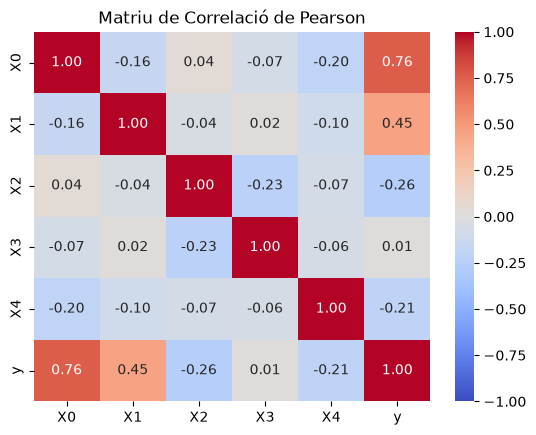

In [6]:

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title("Matriu de Correlació de Pearson")
plt.show()

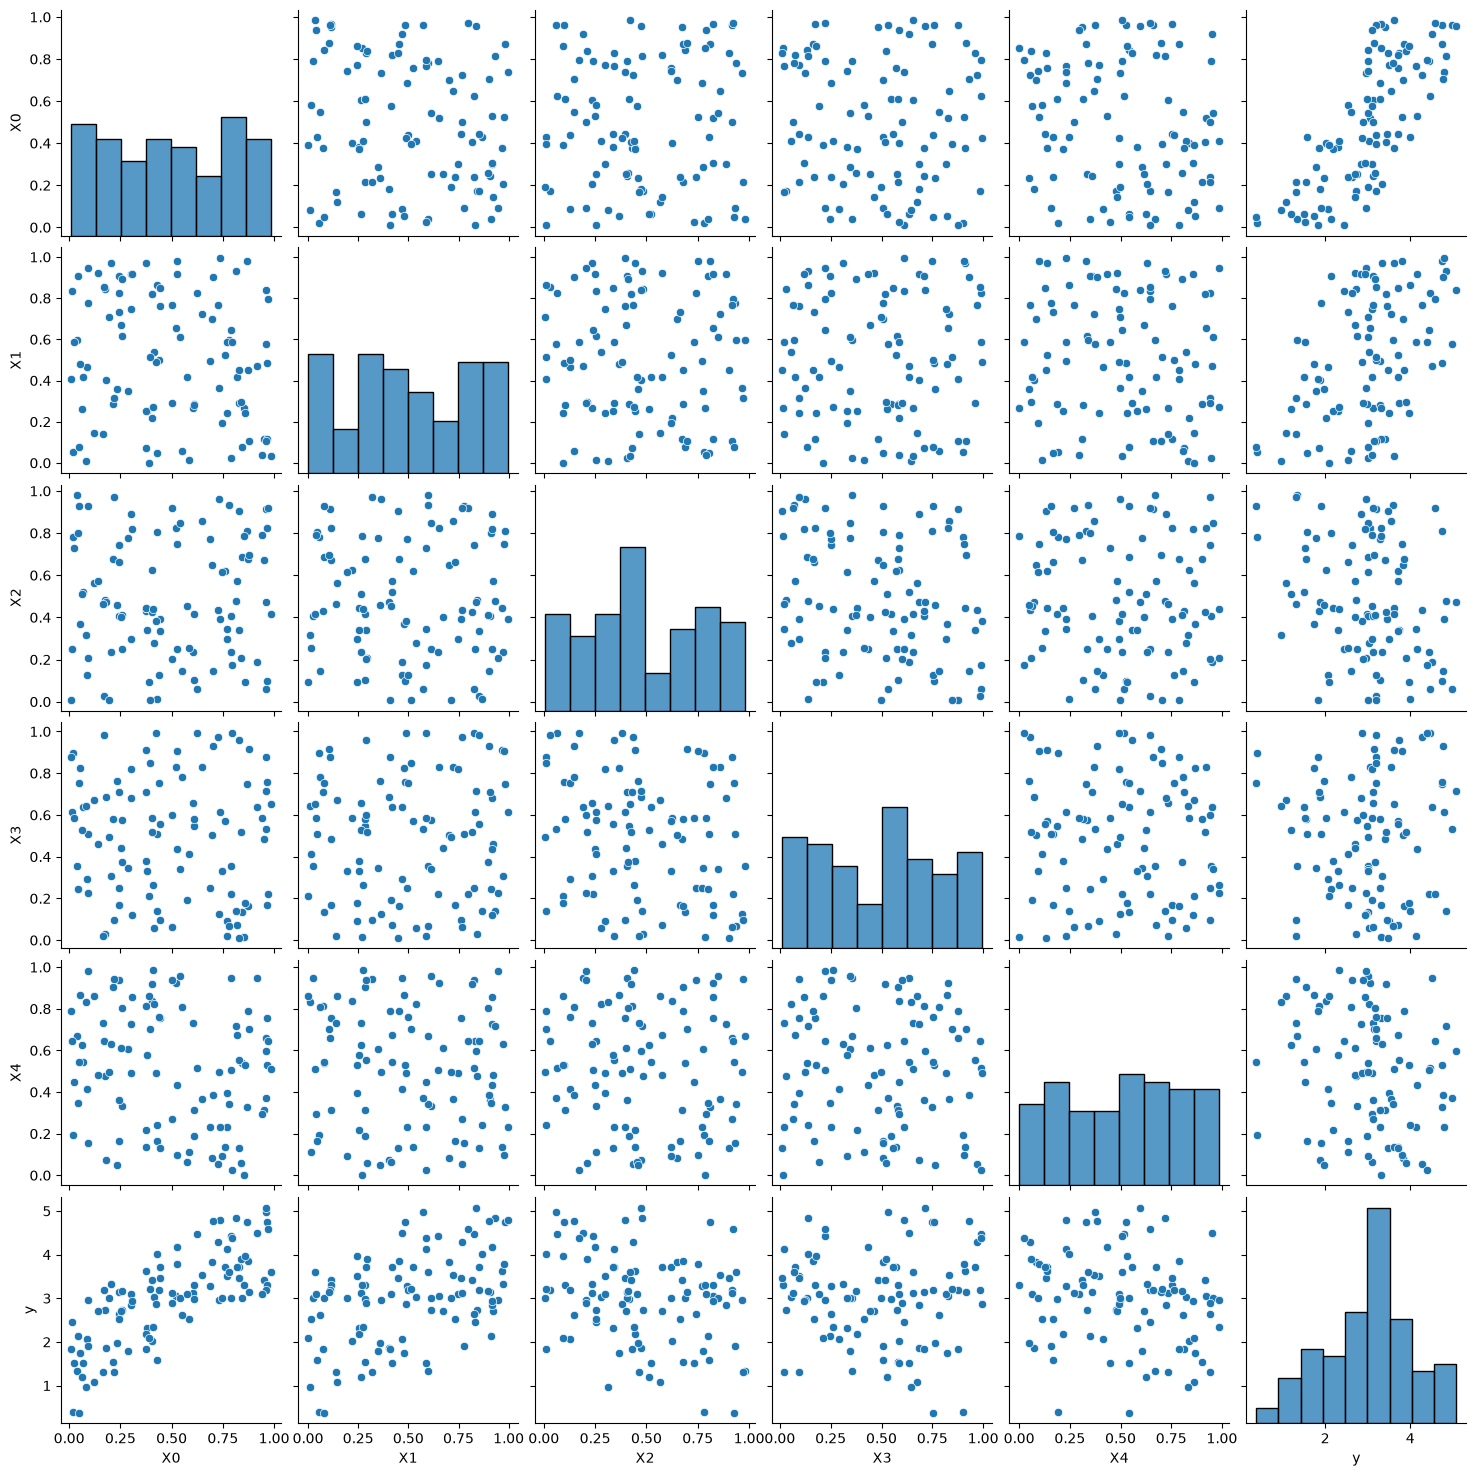

In [7]:

sns.pairplot(data=df)

In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

X = df.drop('y', axis=1)
y = df["y"]
# Dividir les dades en conjunts d'entrenament i prova
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)  # 80% per a entrenament, 20% per a prova

X_train.head()
#y_train.head()

,X0,X1,X2,X3,X4
55,0.053243,0.479383,0.368551,0.824131,0.865906
88,0.259939,0.895218,0.411209,0.373120,0.803588
26,0.818395,0.419354,0.574936,0.074234,0.675734
42,0.962974,0.484303,0.097901,0.758154,0.527702
69,0.939647,0.040237,0.792076,0.583994,0.295954


In [11]:
# https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html


# Crear un model de regressió lineal
model = LinearRegression()
# https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html

# Ajustar el model a les dades d'entrenament
model.fit(X_train, y_train)

# Generar prediccions amb les dades de prova
y_pred = model.predict(X_test)

pd.DataFrame({"y_pred": y_pred, "y_test": y_test})

,y_pred,y_test
83,2.331936,2.335100
53,4.811123,4.799846
70,4.005009,4.002972
45,3.292199,3.297163
44,1.572895,1.575719
39,3.049466,3.045572
22,4.164216,4.165948
80,2.963451,2.963809
10,4.461522,4.472764
0,3.000456,3.001426


In [ ]:
# Avaluar el model utilitzant mètriques
mse = mean_squared_error(y_test, y_pred)  # Calcular l'Error Quadràtic Mitjà (MSE)
rmse = np.sqrt(mse)  # Calcular l'Arrel de l'Error Quadràtic Mitjà (RMSE)
r2 = r2_score(y_test, y_pred)  # Calcular el Coeficient de Determinació (R²)

In [14]:
print(model.intercept_)
print(model.coef_)

1.0039659884576082
[ 2.99942909e+00  1.99882196e+00 -1.00121758e+00  4.24862832e-04
 -3.53351253e-03]


In [15]:
# Imprimir l'equació resultant del model
intercept = model.intercept_  # Obtenir el terme independent (intercepta)
coefficient = model.coef_  # Obtenir el coeficient de la variable X
print(f"Equació del model: y = {coefficient[0]:.4f}X1 +  {intercept:.4f}")

Equació del model: y = 2.9994X1 +  1.0040


In [16]:

# Mostrar mètriques de rendiment del model
print("\nMètriques del Model Lineal:")
print(f"  MSE: {mse:.4f}")  # Imprimir l'MSE amb 4 decimals
print(f"  RMSE: {rmse:.4f}")  # Imprimir l'RMSE amb 4 decimals
print(f"  R²: {r2:.4f}")  # Imprimir l'R² amb 4 decimals


Mètriques del Model Lineal:
  MSE: 0.0000
  RMSE: 0.0043
  R²: 1.0000
